# 04 Feature importance per feature family

Reads the importance tables written by the modelling notebooks (one per run). For the random
forest these are the impurity based importances, for MLP and SGD the permutation importances on
the in domain test split. Importances are summed per family and normalised to a share per run.

Note: impurity importance favours features with many distinct values (here the per source
timing statistics) and is computed on the training capture, so it says what the model *uses*,
not what *transfers*. Notebook 02 (ablation) answers the second question.

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(str(pathlib.Path.cwd()))  # the notebooks live in code/analysis
import analysis_utils as au
importlib.reload(au)

RESULTS = pathlib.Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

EXPS = au.available_experiments()
print('experiments with exported artifacts:', EXPS)
missing = [e for e in au.EXPERIMENTS if e not in EXPS]
if missing:
    print('NOT YET RERUN (no artifacts):', missing)

experiments with exported artifacts: ['E1_apple_same', 'E2_apple_diff', 'E3_samsung_same', 'E4_samsung_diff', 'E5_mixed_same', 'E6_mixed_diff']


In [2]:
rows = []
for e in EXPS:
    for f in sorted((au.ARTIFACT_DIR / e / 'importance').glob('*.csv')):
        label, model, split, frame = f.stem.split('__')
        d = pd.read_csv(f)
        d = d.assign(exp=au.exp_name(e), label=label, model=model, split=split)
        rows.append(d)
imp = pd.concat(rows, ignore_index=True)
imp['family'] = imp['Feature'].map(au.family_of)
imp.to_csv(RESULTS / 'feature_importance_all.csv', index=False)

fam = (imp.groupby(['exp', 'label', 'model', 'split', 'family'])['Importance'].sum().reset_index())
fam['share'] = fam['Importance'] / fam.groupby(['exp', 'label', 'model', 'split'])['Importance'].transform(
    lambda s: s.clip(lower=0).sum())
fam['n_features'] = fam['family'].map(lambda f: len(au.FEATURE_FAMILIES.get(f, [])))
fam['share_per_feature'] = fam['share'] / fam['n_features'].replace(0, np.nan)
fam.to_csv(RESULTS / 'feature_importance_per_family.csv', index=False)
fam[(fam['model'] == 'random_forest') & (fam['label'] == 'multi') & (fam['split'] == 'grouped')] \
    .pivot(index='family', columns='exp', values='share').round(3)

exp,E1 apple same,E2 apple diff,E3 samsung same,E4 samsung diff,E5 mixed same,E6 mixed diff
family,,,,,,
Burst microstructure,0.117,0.202,0.130,0.086,0.063,0.125
Channel and PHY,0.001,0.001,0.000,0.000,0.001,0.001
Joint activity,0.002,0.003,0.002,0.002,0.003,0.001
PDU role,0.050,0.023,0.067,0.077,0.094,0.056
Payload dynamics,0.004,0.004,0.002,0.006,0.003,0.009
Payload shape,0.012,0.021,0.121,0.119,0.085,0.084
Shape and session span,0.176,0.183,0.222,0.275,0.341,0.282
Timing,0.637,0.563,0.456,0.437,0.412,0.443


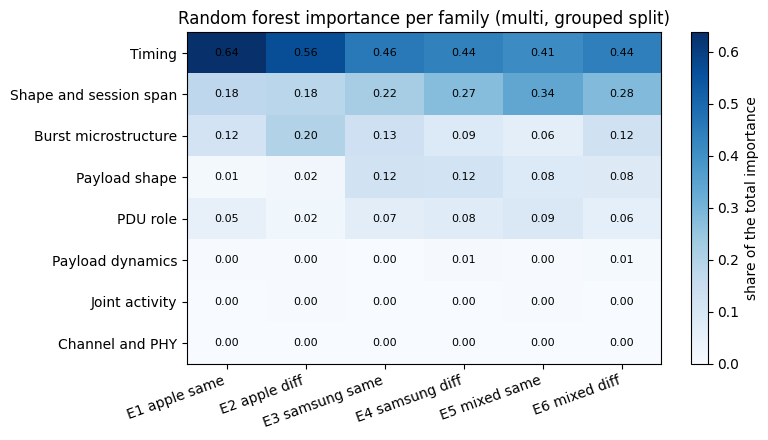

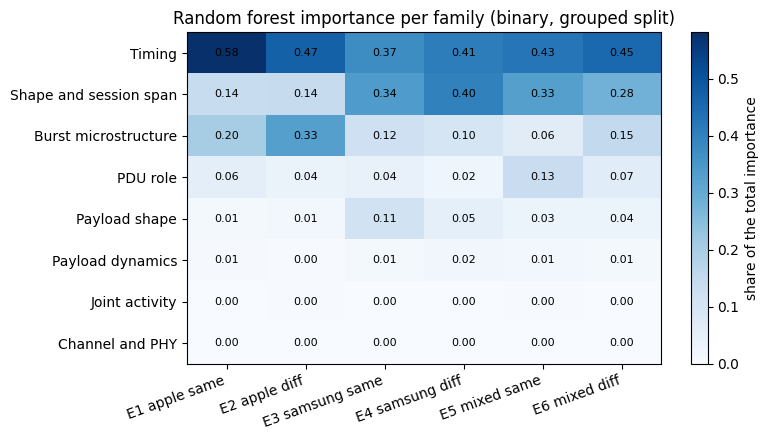

In [3]:
for label in ['multi', 'binary']:
    h = (fam[(fam['model'] == 'random_forest') & (fam['label'] == label) & (fam['split'] == 'grouped')]
         .pivot(index='family', columns='exp', values='share'))
    if h.empty:
        continue
    h = h.loc[h.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(h.values, cmap='Blues', aspect='auto', vmin=0)
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns, rotation=20, ha='right')
    ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            ax.text(j, i, f'{h.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(im, label='share of the total importance')
    ax.set_title(f'Random forest importance per family ({label}, grouped split)')
    plt.tight_layout(); plt.savefig(FIGURES / f'fig_importance_family_{label}.pdf'); plt.show()

## Top ten features per experiment (random forest, three class, grouped split)

In [4]:
top = (imp[(imp['model'] == 'random_forest') & (imp['label'] == 'multi') & (imp['split'] == 'grouped')]
       .sort_values('Importance', ascending=False).groupby('exp').head(10))
top[['exp', 'Feature', 'family', 'Importance']].reset_index(drop=True)

,exp,Feature,family,Importance
0,E1 apple same,iat_median,Timing,0.227698
1,E3 samsung same,iat_median,Timing,0.224461
2,E2 apple diff,iat_std,Timing,0.220393
3,E1 apple same,iat_mean,Timing,0.205402
4,E2 apple diff,iat_mean,Timing,0.200200
5,E1 apple same,iat_std,Timing,0.168859
6,E4 samsung diff,iat_mean,Timing,0.156701
7,E6 mixed diff,iat_median,Timing,0.154911
8,E6 mixed diff,iat_mean,Timing,0.150924
9,E3 samsung same,iat_mean,Timing,0.142702


## Agreement between learners (MLP and SGD use permutation importance)

In [5]:
fam[(fam['label'] == 'multi') & (fam['split'] == 'grouped')] \
    .pivot_table(index='family', columns=['model'], values='share', aggfunc='mean').round(3)

model,multi_layer_perceptron,random_forest,stochastic_gradient_descent
family,,,
Burst microstructure,0.191,0.120,0.071
Channel and PHY,0.004,0.001,-0.001
Joint activity,0.006,0.002,-0.001
PDU role,0.159,0.061,0.314
Payload dynamics,0.016,0.005,0.005
Payload shape,0.059,0.074,0.248
Shape and session span,0.532,0.246,0.353
Timing,0.033,0.491,0.008
